# Chapter 11: Maximum Likelihood and the Invariance Principle

The computational applications of this chapter of *Theory of Statistics*. The code is generated automatically from the book's `code/ch11/` files; see the book for the explanations and proofs.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/izupress/statistical-theory/blob/main/notebooks/ch_11.ipynb)

$$
\newcommand{\R}{\mathbb{R}}\newcommand{\N}{\mathbb{N}}\newcommand{\E}{\mathbb{E}}
\newcommand{\P}{\mathbb{P}}\newcommand{\F}{\mathcal{F}}\newcommand{\I}{\mathbb{I}}
\newcommand{\Var}{\operatorname{Var}}\newcommand{\Cov}{\operatorname{Cov}}
\newcommand{\Corr}{\operatorname{Corr}}\newcommand{\MSE}{\operatorname{MSE}}
\newcommand{\Bias}{\operatorname{Bias}}\newcommand{\Normal}{\mathcal{N}}
\newcommand{\iid}{\overset{\text{i.i.d.}}{\sim}}\newcommand{\pto}{\xrightarrow{P}}
\newcommand{\dto}{\xrightarrow{d}}\newcommand{\X}{\mathbf{X}}\newcommand{\x}{\mathbf{x}}
$$

In [1]:
# Setup: numpy, scipy and matplotlib are preinstalled on Colab. Locally:
#   pip install -r code/requirements.txt
# Figure files (PDF) saved by the code are written to the _figures/ folder; the figures are
# also shown inside the notebook.
import os
os.makedirs("_figures", exist_ok=True)
os.chdir("_figures")
%matplotlib inline

## Analytic and Numerical MLE in the Normal Model; Invariance

*Source file:* `code/ch11/c11_1_normal_analytic_numeric_mle.py`

In [2]:
import numpy as np
from scipy.optimize import minimize

rng = np.random.default_rng(42)
data = rng.normal(10.0, 3.0, size=250)
mu_an, var_an = np.mean(data), np.var(data, ddof=0)
print(f"Analytic MLE: mu={mu_an:.4f}, s2={var_an:.4f}, sd={np.sqrt(var_an):.4f}")

def negll(par, param):
    mu, s = par
    sd = {"sd": abs(s), "var": np.sqrt(abs(s)), "logsd": np.exp(s)}[param]
    return -np.sum(-np.log(sd) - 0.5*np.log(2*np.pi) - (data - mu)**2 / (2*sd**2))

for param, x0 in [("sd", [5, 1]), ("var", [5, 1]), ("logsd", [5, 1])]:
    r = minimize(negll, x0, args=(param,), method="Nelder-Mead", options={"xatol": 1e-8, "fatol": 1e-10})
    mu, s = r.x
    sd = {"sd": abs(s), "var": np.sqrt(abs(s)), "logsd": np.exp(s)}[param]
    print(f"Numerical ({param:5s} param.): mu={mu:.4f}, sd={sd:.4f}, -logL={r.fun:.4f}")

Analytic MLE: mu=9.8540, s2=7.9348, sd=2.8169
Numerical (sd    param.): mu=9.8540, sd=2.8169, -logL=613.6412
Numerical (var   param.): mu=9.8540, sd=2.8169, -logL=613.6412
Numerical (logsd param.): mu=9.8540, sd=2.8169, -logL=613.6412


## Gamma MLE: Newton–Raphson

*Source file:* `code/ch11/c11_2_gamma_mle_newton_raphson.py`

In [3]:
import numpy as np
from scipy.special import digamma, polygamma
from scipy import stats

rng = np.random.default_rng(42)
x = rng.gamma(2.5, 1/0.625, size=400)      # true: alpha=2.5, beta(rate)=0.625; numpy takes scale=1/rate
s = np.log(x.mean()) - np.mean(np.log(x))
a = x.mean()**2 / x.var()                         # MM starting value
print(f"MM start: alpha={a:.5f}")
for k in range(6):
    a -= (np.log(a) - digamma(a) - s) / (1/a - polygamma(1, a))
    print(f"iter {k+1}: alpha={a:.8f}")
b = a / x.mean()                                  # beta_hat = alpha_hat / xbar (rate)
a_sp, _, scale_sp = stats.gamma.fit(x, floc=0)    # scipy also returns the scale
print(f"Newton MLE : alpha={a:.5f}, beta(rate)={b:.5f}")
print(f"scipy.fit  : alpha={a_sp:.5f}, beta(rate)={1/scale_sp:.5f}")

MM start: alpha=2.52321
iter 1: alpha=2.54125944
iter 2: alpha=2.54139646
iter 3: alpha=2.54139646
iter 4: alpha=2.54139646
iter 5: alpha=2.54139646
iter 6: alpha=2.54139646
Newton MLE : alpha=2.54140, beta(rate)=0.63481
scipy.fit  : alpha=2.54140, beta(rate)=0.63481


## Multimodality of the Cauchy Likelihood

*Source file:* `code/ch11/c11_3_cauchy_multimodal_likelihood.py`

Local maxima: [-3.12   0.252  5.658]
start=-5.00 -> theta_hat=-3.1171, logL=-12.2092
start= 0.00 -> theta_hat= 0.2503, logL=-12.5762
start= 6.00 -> theta_hat= 5.6581, logL=-12.6432
start= 0.40 -> theta_hat= 0.2503, logL=-12.5762
start=-3.12 -> theta_hat=-3.1171, logL=-12.2092


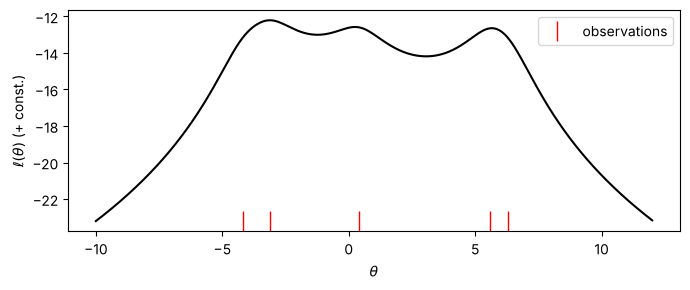

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar, minimize

x = np.array([-4.2, -3.1, 0.4, 5.6, 6.3])
ll = lambda t: -np.sum(np.log1p((x - t)**2))
grid = np.linspace(-10, 12, 4001)
L = np.array([ll(t) for t in grid])
peaks = grid[1:-1][(L[1:-1] > L[:-2]) & (L[1:-1] > L[2:])]
print("Local maxima:", np.round(peaks, 3))
for t0 in [-5.0, 0.0, 6.0, np.median(x), grid[np.argmax(L)]]:   # the last two: the median and the best grid point
    r = minimize(lambda t: -ll(t[0]), [t0], method="BFGS")
    print(f"start={t0:5.2f} -> theta_hat={r.x[0]:7.4f}, logL={-r.fun:.4f}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(grid, L, "k-")
ax.plot(x, np.full_like(x, L.min()), "r|", ms=15, label="observations")
ax.set_xlabel(r"$\theta$"); ax.set_ylabel(r"$\ell(\theta)$ (+ const.)"); ax.legend()
fig.tight_layout(); fig.savefig("cauchy_ll.pdf")